# EXP-E2-03 : quelle méthode pour les sites connus ?

**Question.** Pour un compteur déjà suivi, quelle méthode prévoit le mieux les 24 heures du lendemain avec ce qui est publié à minuit ? On compare un MLP (deep learning), un HGB (gradient boosting) et deux références simples.

**Règle de décision, figée le 2026-11-24 avant les scores** ([fiche](../reports/experiments/EXP-E2-03.md), D-26) :
1. un modèle n'est retenu que s'il fait au moins **5 %** de mieux que la meilleure référence (MAE macro) et s'il est meilleur sur **plus de la moitié** des compteurs ;
2. entre MLP et HGB, on ne choisit le MLP que si l'écart dépasse l'étendue entre ses 3 graines. Sinon, on prend le **HGB**, plus simple.

**Données.** 6 014 cas de validation (97 compteurs × 62 jours, juillet-août 2026). Modèles appris jusqu'au 01/07/2026. Score : le calcul d'E4 (`src/eval/metrics.py`), refait par `score.py`.

Ce notebook ne contient pas de calcul propre : il appelle `predict.py`, `score.py` et `demo.py`, qui sont testés.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.models.known import batch as B
from src.models.known import demo as D
from src.models.known import predict as P
from src.models.known import score as S

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
SNAPSHOT = "hist-20261117"
PRED = P.data_path("predictions")

NAMES = {
    "e2-hgb-ctx-20260701-s0-b357": "HGB",
    "e2-mlp-ctx-20260701-s0-9ce9": "MLP graine 0",
    "e2-mlp-ctx-20260701-s1-9318": "MLP graine 1",
    "e2-mlp-ctx-20260701-s2-6278": "MLP graine 2",
    "e2-reference_profile-measured": "Médiane 4 semaines",
    "e2-reference-measured": "Même heure J-7",
}

## 1. Les scores

Calculés par `python -m src.models.known.score --experiment EXP-E2`, qui lit les prévisions du zip livré à E4.

In [2]:
scores = json.loads((PRED / "EXP-E2" / "scores_known_site_validation.json").read_text())
tables = {k: pd.DataFrame(v).T.rename(index=NAMES) for k, v in scores["scores"].items()}
cols = ["mae_macro", "bias", "rmse", "n_counters", "n_compared_cases", "coverage_24h", "n_fallback_cases"]
tables["système"][cols].sort_values("mae_macro")

,mae_macro,bias,rmse,n_counters,n_compared_cases,coverage_24h,n_fallback_cases
MLP graine 0,22.232,-0.815,47.05,95,5613,1.0,320
HGB,22.254,-1.126,49.065,95,5613,1.0,0
MLP graine 1,22.347,0.693,48.101,95,5613,1.0,320
MLP graine 2,22.589,-0.266,48.076,95,5613,1.0,320
Médiane 4 semaines,27.012,8.471,56.574,95,5613,1.0,204
Même heure J-7,29.746,2.385,64.163,95,5613,1.0,628


In [3]:
official = Path("data/evaluation/proto-v1/EXP-E2/scores.csv")
if official.exists():
    e4 = pd.read_csv(official)
    e4 = e4[e4.comparison_population_id.str.endswith("common_complete")].set_index("method_run_id")
    check = pd.DataFrame({"E2 (score.py)": pd.DataFrame(scores["scores"]["système"]).T["mae_macro"],
                          "E4 (scores.csv)": e4["mae_macro"]}).astype(float)
    check["écart"] = check.iloc[:, 0] - check.iloc[:, 1]
    display(check.rename(index=NAMES).round(4))
else:
    print("scores.csv d'E4 absent de cette copie (il est sur dev, dans data/evaluation/proto-v1/EXP-E2/)")

,E2 (score.py),E4 (scores.csv),écart
HGB,22.254,22.254,-0.0
MLP graine 0,22.232,22.232,-0.0
MLP graine 1,22.347,22.347,0.0
MLP graine 2,22.589,22.589,-0.0
Même heure J-7,29.746,29.746,-0.0
Médiane 4 semaines,27.012,27.012,0.0


## 2. La règle de décision, appliquée telle quelle

In [4]:
sys_t = pd.DataFrame(scores["scores"]["système"]).T
counters = pd.read_csv(PRED / "EXP-E2" / "scores_known_site_validation_by_counter.csv")
by = counters[counters.lecture == "système"].pivot_table(index="counter_id", columns="method_run_id", values="MAE")
refs = ["e2-reference-measured", "e2-reference_profile-measured"]
best_ref = sys_t.loc[refs, "mae_macro"].astype(float).idxmin()
rows = []
for m in ["e2-hgb-ctx-20260701-s0-b357", "e2-mlp-ctx-20260701-s0-9ce9", "e2-mlp-ctx-20260701-s1-9318", "e2-mlp-ctx-20260701-s2-6278"]:
    gain = 1 - float(sys_t.loc[m, "mae_macro"]) / float(sys_t.loc[best_ref, "mae_macro"])
    share = (by[m] < by[best_ref]).mean()
    rows.append({"méthode": NAMES[m], "gain vs meilleure référence": f"{gain:.1%}",
                 "compteurs meilleurs": f"{share:.0%}", "règle 1": "oui" if gain >= 0.05 and share > 0.5 else "non"})
print("meilleure référence :", NAMES[best_ref])
display(pd.DataFrame(rows))
mlp = sys_t.loc[[c for c in sys_t.index if "mlp" in c], "mae_macro"].astype(float)
spread = mlp.max() - mlp.min()
diff = float(sys_t.loc["e2-mlp-ctx-20260701-s0-9ce9", "mae_macro"]) - float(sys_t.loc["e2-hgb-ctx-20260701-s0-b357", "mae_macro"])
print(f"règle 2 : MLP graine 0 - HGB = {diff:+.3f} ; étendue entre graines du MLP = {spread:.3f}")
print("=> décision :", "MLP" if diff < -spread else "HGB (écart plus petit que la variabilité du MLP)")

meilleure référence : Médiane 4 semaines


,méthode,gain vs meilleure référence,compteurs meilleurs,règle 1
0,HGB,17.6%,97%,oui
1,MLP graine 0,17.7%,93%,oui
2,MLP graine 1,17.3%,94%,oui
3,MLP graine 2,16.4%,94%,oui


règle 2 : MLP graine 0 - HGB = -0.022 ; étendue entre graines du MLP = 0.357
=> décision : HGB (écart plus petit que la variabilité du MLP)


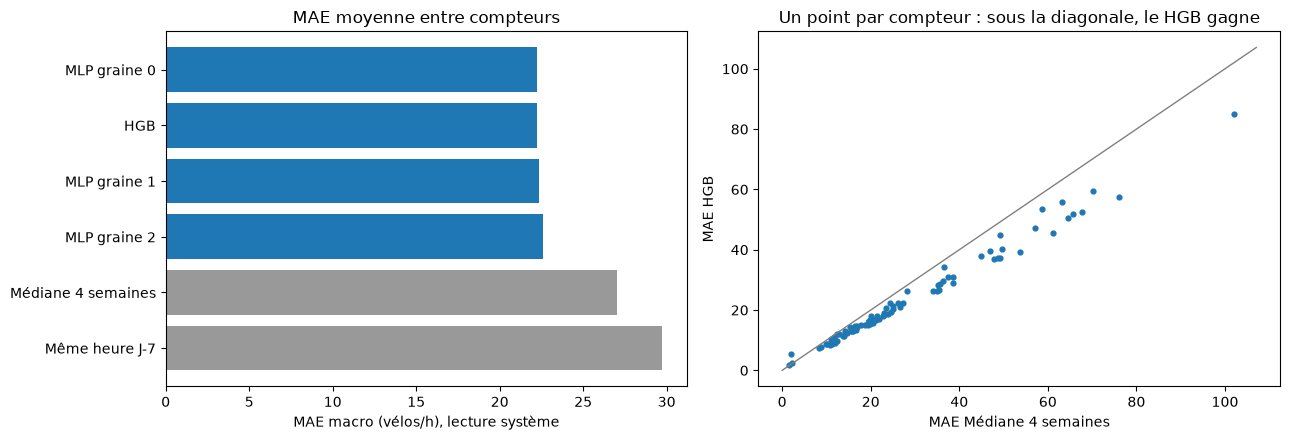

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
t = tables["système"].sort_values("mae_macro")
axes[0].barh(t.index, t["mae_macro"].astype(float), color=["C0" if "HGB" in i or "MLP" in i else "0.6" for i in t.index])
axes[0].invert_yaxis(); axes[0].set_xlabel("MAE macro (vélos/h), lecture système"); axes[0].set_title("MAE moyenne entre compteurs")
x, y = by[best_ref], by["e2-hgb-ctx-20260701-s0-b357"]
axes[1].scatter(x, y, s=12)
lim = [0, max(x.max(), y.max()) * 1.05]
axes[1].plot(lim, lim, color="0.5", lw=1)
axes[1].set_xlabel(f"MAE {NAMES[best_ref]}"); axes[1].set_ylabel("MAE HGB")
axes[1].set_title("Un point par compteur : sous la diagonale, le HGB gagne")
plt.tight_layout()

## 3. Le gain est-il solide ?

Trois questions : le gain vient-il des heures faciles (la nuit) ? Tient-il d'un mois à l'autre ? Quel est son intervalle de confiance ? On tire des **jours** avec remise (bootstrap), parce que les heures d'un même jour sont corrélées. Le calcul (`robustness.py`) prend environ 1 min.

In [6]:
from src.models.known import robustness as R
models = ["e2-hgb-ctx-20260701-s0-b357", "e2-mlp-ctx-20260701-s0-9ce9", *refs]
fc = S.load_forecasts(PRED / "EXP-E2", models)
wide = R.paired_hours(fc, S.load_observations(S.load_cases()), models)
R.by_band(wide, models).rename(columns=lambda c: " ".join(NAMES.get(x, x) for x in c.split())).round(2)

,heures,vélos/h moyen,MAE HGB,WAPE HGB,MAE MLP graine 0,WAPE MLP graine 0,MAE Même heure J-7,WAPE Même heure J-7,MAE Médiane 4 semaines,WAPE Médiane 4 semaines
tranche,,,,,,,,,,
toutes les heures,133624,86.11,22.48,0.26,22.44,0.26,30.04,0.35,27.39,0.32
nuit 0-6 h,33166,23.55,9.57,0.41,9.26,0.39,11.98,0.51,10.30,0.44
pointe matin 7-9 h,11136,87.46,33.30,0.38,30.50,0.35,43.00,0.49,41.65,0.48
pointe soir 17-19 h,11182,173.83,36.57,0.21,38.04,0.22,49.50,0.28,48.13,0.28
reste de la journée,78140,99.91,24.41,0.24,24.65,0.25,33.07,0.33,29.64,0.30


In [7]:
rows = []
for label, part in [("ensemble", wide), ("juillet", wide[wide.day.str.startswith("2026-07")]), ("août", wide[wide.day.str.startswith("2026-08")])]:
    for ref in refs:
        b = R.bootstrap_gain(part, "e2-hgb-ctx-20260701-s0-b357", ref)
        rows.append({"période": label, "référence": NAMES[ref], "MAE HGB": R.macro_mae(part, "e2-hgb-ctx-20260701-s0-b357"),
                     "MAE référence": R.macro_mae(part, ref), "gain": b["gain"], "IC 95 % bas": b["low"], "IC 95 % haut": b["high"]})
display(pd.DataFrame(rows).round(3))
print("Face à J-7, le gain est stable. Face à la médiane, il vient surtout d'août, où la médiane est en retard sur la baisse des vacances.")

,période,référence,MAE HGB,MAE référence,gain,IC 95 % bas,IC 95 % haut
0,ensemble,Même heure J-7,22.254,29.746,0.252,0.198,0.307
1,ensemble,Médiane 4 semaines,22.254,27.012,0.176,0.105,0.249
2,juillet,Même heure J-7,29.803,40.553,0.265,0.190,0.336
3,juillet,Médiane 4 semaines,29.803,31.592,0.057,-0.031,0.137
4,août,Même heure J-7,14.496,18.566,0.219,0.148,0.285
5,août,Médiane 4 semaines,14.496,22.493,0.356,0.262,0.437


Face à J-7, le gain est stable. Face à la médiane, il vient surtout d'août, où la médiane est en retard sur la baisse des vacances.


## 4. Un cas en direct

Pour un autre cas, il suffit de changer `COUNTER` et `DAY` (un jour de juillet-août 2026). Le calcul passe par `predict_24h`, le même code que l'application. La vérité n'est montrée que sur le graphique, elle n'est jamais donnée aux méthodes. Le chargement des mesures prend environ 15 s.

,MAE,statut,raison
method,,,
HGB,140.894,ok,None
MLP,115.930,ok,None
Médiane 4 semaines,76.417,ok,None
Même heure J-7,243.958,ok,None


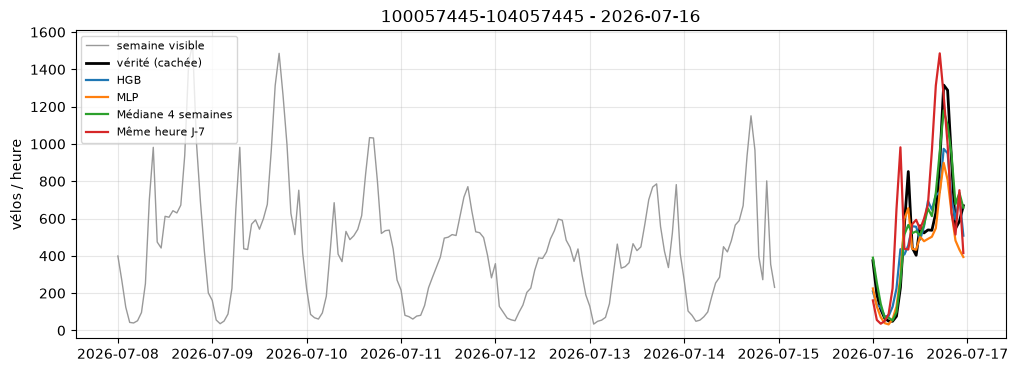

In [8]:
COUNTER = "100057445-104057445"   # Totem 73 boulevard de Sébastopol S-N
DAY = "2026-07-16"                  # un jeudi ordinaire

cases = pd.read_csv("data/evaluation/proto-v1/cases.csv", dtype=str, keep_default_na=False)
loader = P.counts_history_loader(SNAPSHOT)
context = P.load_context(SNAPSHOT)
VARIANTS = {"HGB": {"variant": "hgb"}, "MLP": {"variant": "mlp"},
            "Médiane 4 semaines": {"variant": "reference_profile"}, "Même heure J-7": {"variant": "reference"}}

def show(counter, day):
    case = D.find_case(cases, counter, day)
    history = loader(counter)
    fc = D.forecast_case(case, history, VARIANTS, context=context)
    view = D.case_view(case, history)
    D.plot_case(view, fc, title=f"{counter} - {day}")
    truth = view["truth"].set_index("timestamp")["count"]
    err = fc.assign(truth=fc.target_timestamp.map(truth)).assign(err=lambda d: (d.y_pred - d.truth).abs())
    return err.groupby("method", sort=False).agg(MAE=("err", "mean"), statut=("prediction_status", "first"),
                                                 raison=("status_reason", "first"))

show(COUNTER, DAY)

,MAE,statut,raison
method,,,
HGB,175.354,ok,None
MLP,116.732,ok,None
Médiane 4 semaines,215.167,ok,None
Même heure J-7,246.833,ok,None


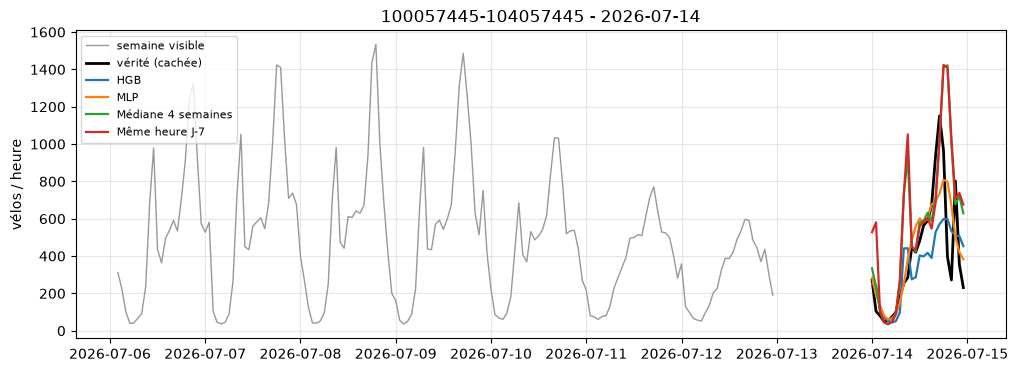

In [9]:
show(COUNTER, "2026-07-14")  # 14 juillet, jour férié

Un **cas de repli** : ce compteur a été en panne une bonne partie de la semaine précédente. Sa semaine visible a moins de 84 h mesurées, alors le MLP refuse et la référence prend le relais, avec la raison exacte. Le HGB, lui, sert le cas : ses variables tolèrent les manques.

,MAE,statut,raison
method,,,
HGB,26.033,ok,None
MLP,18.458,fallback,mlp_window_too_sparse
Médiane 4 semaines,19.083,ok,profile_weeks_missing
Même heure J-7,18.458,fallback,lag168_missing


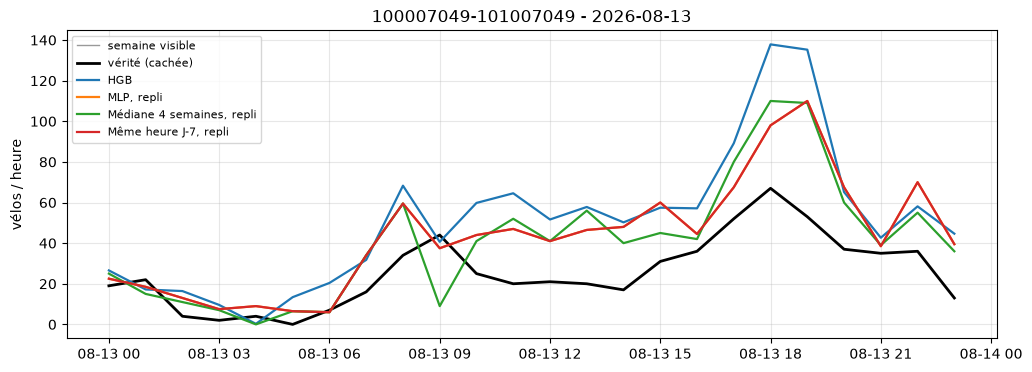

In [10]:
show("100007049-101007049", "2026-08-13")

Un **cas d'échec venu des données** : le même compteur de Sébastopol, le jeudi 09/07. Ce jour-là, les mesures d'E1 sont **décalées de 2 heures** : le pic du matin tombe à 7 h au lieu de 9 h, et le 02/07 est décalé dans l'autre sens. Aucune méthode ne peut prévoir un tel décalage. Le défaut est consigné dans le suivi (§8) pour E1.

,MAE,statut,raison
method,,,
HGB,225.539,ok,None
MLP,237.165,ok,None
Médiane 4 semaines,233.708,ok,None
Même heure J-7,350.729,fallback,lag168_missing


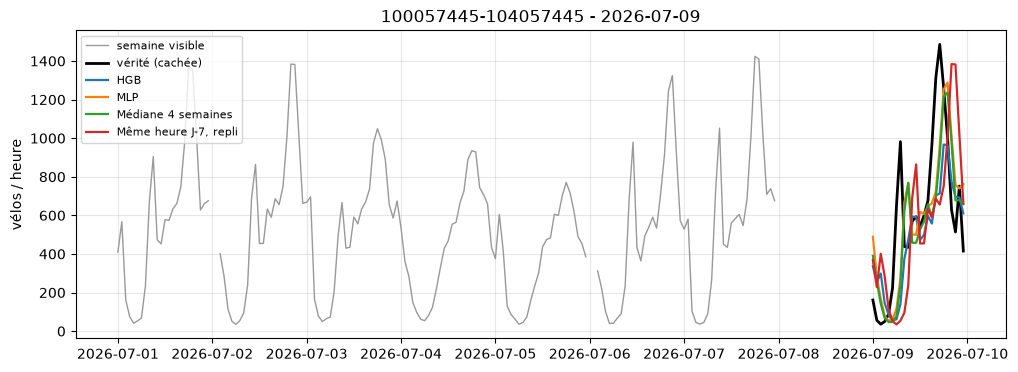

In [11]:
show(COUNTER, "2026-07-09")

## 5. Replis et cas d'échec sur les 6 014 cas

In [12]:
import zipfile
runs = []
with zipfile.ZipFile(PRED / "EXP-E2" / "EXP-E2-predictions.zip") as zf:
    for name in zf.namelist():
        if name.endswith(".runs.csv"):
            runs.append(pd.read_csv(zf.open(name), dtype=str, keep_default_na=False))
runs = pd.concat(runs)
runs["méthode"] = runs.method_run_id.map(NAMES)
reason = runs.status_reason.str.replace(r"^\d+/24 horizons en repli$", "repli partiel de la référence", regex=True)
runs["statut"] = runs.status.where(reason == "", runs.status + " : " + reason)
pd.crosstab(runs["méthode"], runs["statut"])

statut,fallback : mlp_window_too_sparse,fallback : repli partiel de la référence,ok
méthode,,,
HGB,0,0,6014
MLP graine 0,320,0,5694
MLP graine 1,320,0,5694
MLP graine 2,320,0,5694
Médiane 4 semaines,0,204,5810
Même heure J-7,0,628,5386


In [13]:
inv = pd.read_csv(f"data/processed/{SNAPSHOT}/inventory_quality.csv", dtype=str).drop_duplicates("counter_id").set_index("counter_id")
worst = by[["e2-hgb-ctx-20260701-s0-b357", best_ref]].rename(columns=NAMES)
worst["nom"] = inv.reindex(worst.index)["counter_name"]
worst["profil"] = inv.reindex(worst.index)["profile_type"]
worst.sort_values("HGB", ascending=False).head(8)

method_run_id,HGB,Médiane 4 semaines,nom,profil
counter_id,,,,
100057445-104057445,84.857,101.972,Totem 73 boulevard de Sébastopol S-N,pendulaire
100057445-103057445,59.324,70.209,Totem 73 boulevard de Sébastopol N-S,pendulaire
100050876-104050876,57.566,75.987,Totem 64 Rue de Rivoli O-E,mixte
100056335-104056335,55.809,63.120,Quai d'Orsay E-O,mixte
100056336-103056336,53.551,58.668,27 quai de la Tournelle SE-NO,pendulaire
100047533-101047533,52.438,67.616,89 boulevard de Magenta NO-SE,mixte
100047536-101047536,51.901,65.698,102 boulevard de Magenta SE-NO,mixte
100050876-103050876,50.585,64.503,Totem 64 Rue de Rivoli E-O,pendulaire


## 6. Tout recalculer (optionnel)

Il faut passer `RECALCULER = True`. Le score complet prend environ 5 min et redonne le tableau de la section 1.

In [14]:
RECALCULER = False
if RECALCULER:
    again = S.score_experiment(PRED / "EXP-E2")
    display(again["système"].rename(index=NAMES))